# SVD-SNO: локальное обучение

Входные A,n проецируем на независимые train-only POD-базисы. Их численные ранги не ограничивают ранг выходного поля. Направление задаём через cos/sin, k нормируем по train. Сеть нелинейно смешивает коэффициенты, затем восстанавливает Re/Im в исходных FEM-узлах. У Re/Im сохраняются собственные численные ранги; нулевое дополнение используется лишь внутри двухканального выхода сети.

Это адаптация SNO с обучаемым по данным спектральным представлением. Она не объявляется точным воспроизведением SNO или PODNO. В отличие от исходника, loss и выбор выходного ранга используют consistent FEM L2. Сам POD использует mass-lumped веса, поэтому projection error отдельно измеряется в FEM-норме.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
BASE = ROOT / 'neural_operator'
DATA_DIR = BASE / 'data' / 'low_frequency'
RUNS = BASE / 'runs' / 'low_frequency'
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_operator.data import load_dataset
from neural_operator.plotting import display_table, plot_prediction, plot_history


## Конфигурация и запуск

Первое выполнение обучает модель на локальном CPU. Повторное загружает только завершённый запуск с теми же данными и конфигурацией. `RETRAIN=True` запускает новое обучение; автоматического resume нет. Лучшая эпоха определяется по validation. Лимит эпох не означает сходимость. На каждой модели одинаковы split, seed и максимальный budget эпох, но числа параметров отличаются.


In [2]:
from neural_operator.training import TrainConfig, run_experiment
METHOD = 'svd'
RETRAIN = False
CONFIG = TrainConfig(method=METHOD, epochs=200, batch_size=32, width=24, depth=3,
                     rank=48, input_rank=32, resolution=32, modes=8, seed=42, threads=2)
dataset = load_dataset(DATA_DIR)
OUT = RUNS / METHOD
predictor, metrics, history = run_experiment(dataset, OUT, CONFIG, retrain=RETRAIN)
print(json.dumps(metrics, indent=2, ensure_ascii=False))


Loaded completed local svd run: /workspace/multiscale-fem-scattering/neural_operator/runs/low_frequency/svd


{
  "method": "svd",
  "field": "scattered",
  "metric": "consistent_complex_FEM_L2",
  "dataset_fingerprint": "643f882b18d6e82cb75552e8dacb245c72eab30da13a1eff40ee0f97d0ce9746",
  "config": {
    "method": "svd",
    "epochs": 200,
    "batch_size": 32,
    "learning_rate": 0.002,
    "width": 24,
    "depth": 3,
    "rank": 48,
    "input_rank": 32,
    "target_projection_error": 0.01,
    "pod_method": "full",
    "resolution": 32,
    "modes": 8,
    "padding": 8,
    "patience": 50,
    "min_epochs": 50,
    "seed": 42,
    "threads": 2,
    "device": "cpu"
  },
  "train_samples": 128,
  "val_samples": 32,
  "test_samples": 32,
  "completed_epochs": 58,
  "best_epoch": 8,
  "best_val_fem_l2": 0.9966935515403748,
  "stop_reason": "validation_plateau",
  "parameters": 68666,
  "preprocessing_seconds": 0.2689833330005058,
  "training_seconds": 4.987941920000594,
  "test_batch_seconds": 0.0025481250013399404,
  "test_seconds_per_sample": 7.962890629187314e-05,
  "test_fem_l2": {
    "

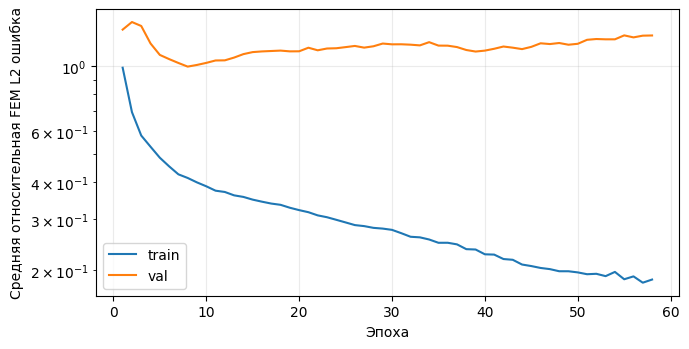

method,mean,median,p95,max,best_epoch,epochs,parameters
svd,0.68581,0.63056,1.0659,1.184,8,58,68666


In [3]:
figure = plot_history(history)
figure.savefig(OUT / 'history.png', dpi=160)
plt.show()
display_table([{'method': METHOD, **metrics['test_fem_l2'], 'best_epoch': metrics['best_epoch'],
                'epochs': metrics['completed_epochs'], 'parameters': metrics['parameters']}])


Ранги: {'A': 24, 'n': 24, 'real': 48, 'imag': 48}
Validation projection target attained: False


quantity,mean,median,p95,max
POD reconstruction in FEM L2,0.026684,0.026487,0.047385,0.048382
Network prediction in FEM L2,0.68581,0.63056,1.0659,1.184


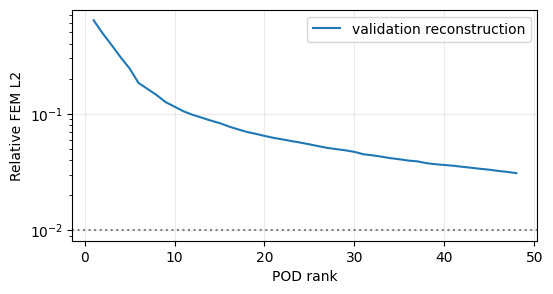

In [4]:
print('Ранги:', metrics['ranks'])
print('Validation projection target attained:', metrics['rank_target_attained'])
display_table([{'quantity': 'POD reconstruction in FEM L2', **metrics['projection_fem_l2']},
               {'quantity': 'Network prediction in FEM L2', **metrics['test_fem_l2']}])
rank_info = predictor.preprocessing['rank_validation']
plt.figure(figsize=(6, 3))
plt.semilogy(rank_info['ranks'], rank_info['mean_fem_l2'], label='validation reconstruction')
plt.axhline(rank_info['target'], color='gray', linestyle=':')
plt.xlabel('POD rank'); plt.ylabel('Relative FEM L2'); plt.grid(alpha=.25); plt.legend(); plt.show()


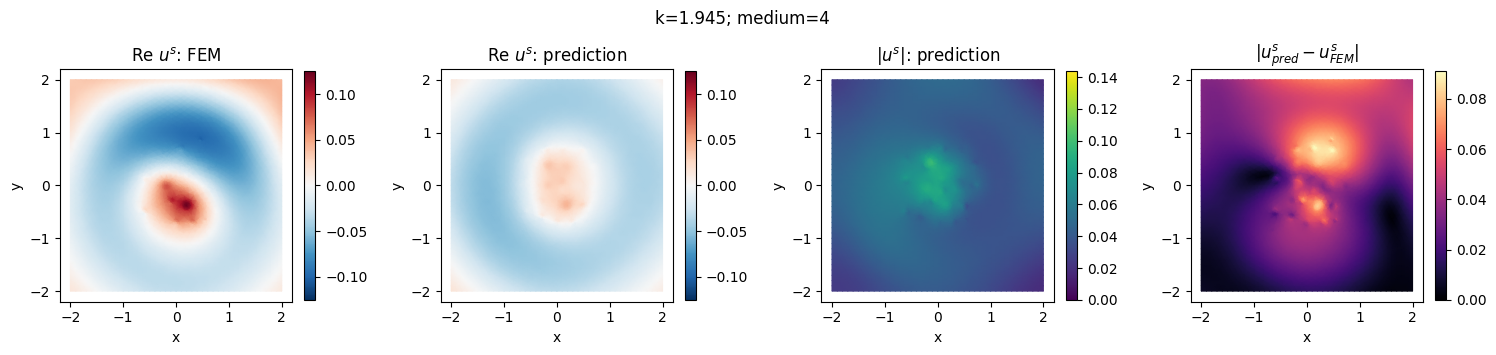

Self-contained checkpoint: /workspace/multiscale-fem-scattering/neural_operator/runs/low_frequency/svd/model.pt


In [5]:
test = dataset.split_indices()[2]
index = int(test[0])
prediction = predictor.predict_dataset(dataset, [index])[0]
figure = plot_prediction(dataset, index, prediction)
figure.savefig(OUT / 'prediction.png', dpi=160)
plt.show()
print('Self-contained checkpoint:', OUT / 'model.pt')


Модель, базисы, нормализация, геометрия и архитектура находятся в одном `model.pt`; история и метрики сохранены рядом. Отдельный [Inference.ipynb](Inference.ipynb) загружает этот файл в чистом ядре. Сопоставление всех методов: [Comparison.ipynb](Comparison.ipynb). На 48 средах это пилотный запуск; малый train loss не подтверждает перенос на новые среды.
